In [1]:
#import

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

Matplotlib is building the font cache; this may take a moment.


In [2]:
#parametros

mp = 0.8
cp = 500
ma = 1
ca = 4186
har = 10
r = 0.09
H = 0.1
Aplateral = (2*np.pi*r*H)
Ap = (2*np.pi*r*H+np.pi*r**2)
Apanelaaberta = (np.pi*r**2)
Kaco = 16
d = 0.001
P = 1500
efi = 0.85
Tamb = 25

In [3]:
#modelo



R1 = 1 / (har * Aplateral)
R2 = (d / 2) / (Kaco * Aplateral)
R3 = (d / 2) / (Kaco * Ap)
R4 = 1 / (har * Apanelaaberta)



def modelo_a(x, t):
    Tp = x[0]
    Ta = x[1]  
    Q1 = P*efi
    Q2 = ((Tp-Ta)/R3)
    Q3 = ((Tp-Tamb)/(R1+R2))
    Q4 = ((Ta-Tamb)/R4)
    dUpdt = (1/(mp*cp)) * (Q1-Q2-Q3)
    dUadt = (1/(ma*ca)) * (Q2-Q4)
    dydt = [dUpdt, dUadt]
    return dydt

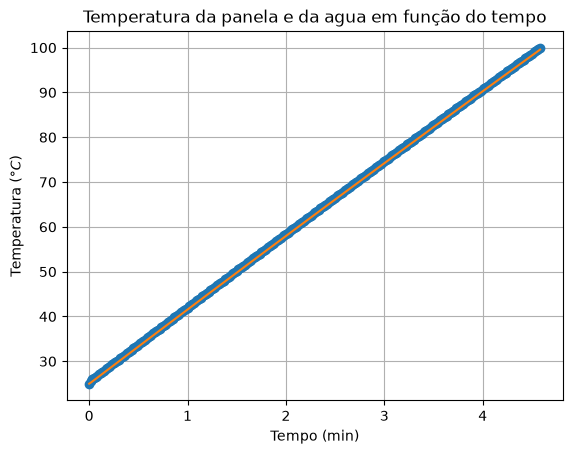

In [4]:
Tp0 = 25
Tambi = 25
x0 = [Tp0, Tambi]

dt = 1
tempo = np.arange(0, 3600+dt, dt)

x_lista = odeint(modelo_a, x0,tempo)
Tp_lista = x_lista[:,0]
Ta_lista = x_lista[:,1]

tempo_grafico = []
Tp_grafico = []
Ta_grafico = []

i = 0
while i < len(Tp_lista) and Tp_lista[i] < 100:
    tempo_grafico.append(tempo[i] / 60)
    Tp_grafico.append(Tp_lista[i])
    Ta_grafico.append(Ta_lista[i])
    i += 1

plt.plot(tempo_grafico, Tp_grafico,'--o', label='Panela')
plt.plot(tempo_grafico, Ta_grafico,label='Agua')
plt.title('Temperatura da panela e da agua em função do tempo')
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura ($°C$)')
plt.grid()
plt.show()